# XGBoost model: NAFLD significant fibrosis prediction

**Task:** Binary classification of significant fibrosis (stage ≥ 2) in NAFLD patients,
from routine clinical and laboratory values.  
**Dataset:** `data/NAFLD_clean.xlsx` — the EDA-cleaned version (605 patients, 67 columns,
pre-computed helper columns already present).  
**This notebook:** trains and evaluates XGBoost (baseline + tuned) following the same
pipeline structure used by the Logistic Regression and Random Forest teammates.

### Rules that keep the three models comparable
| Item | Shared value |
|---|---|
| Inputs | `feats` (33 columns) from the setup section |
| Split | 80/20, `stratify=strata`, `random_state=42` |
| Preprocessing | same `pre` pipeline (median fill, scaling, one-hot smoking, no missing-value flags) |
| Repeated CV | 5 folds × 5 repeats, `random_state=42`, stratified on `s_train` |
| Out-of-fold folds | 5 folds, shuffled, `random_state=42`, stratified on `s_train` |
| Tuning | 40 random-search candidates |
| Test set | **not touched here** — evaluated once after all models are final |

Run cells top-to-bottom. Use **Restart & Run All** before committing.

## 0. Imports

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import xgboost
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'xgboost'])

from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
    cross_validate, cross_val_predict, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss
from sklearn.base import clone
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print('Libraries loaded OK')

Libraries loaded OK


## 1. Load the cleaned dataset and rebuild the shared setup

`NAFLD_clean.xlsx` is the EDA-cleaned file — biopsy targets, helper columns (`n_panel`,
`in_panel`, `FIB4`, `FibGroup`, `AtRiskNASH_calc`) are already present so we do **not**
recompute them here. We only pull the feature list and targets.

Expected printed checks: `(605, 67)` / `50` / `15 35` / `33 27 5`.

In [2]:
# 1. Load the clean dataset
CLEAN_PATH = 'data/NAFLD_clean.xlsx'
data = pd.read_excel(CLEAN_PATH)
print('Loaded from:', CLEAN_PATH, data.shape)         # expect (605, 67)

# 2. Columns that must NEVER enter the model (biopsy-derived or bookkeeping)
biopsy_cols = [
    'Steatosis', 'Activity', 'Fibrosis', 'NAS', 'AtRiskNASH', 'AtRiskNASH_calc',
    'FibrosisStatus', 'SigFibrosis', 'AdvFibrosis', 'Cirrhosis',
    'SAF_Diagnosis', 'TypeOfDisease', 'FibGroup'
]
id_cols = ['Patient No.', 'n_panel', 'in_panel', 'FIB4']

# 3. All candidate feature columns (50 total)
feature_cols = [c for c in data.columns if c not in biopsy_cols + id_cols]
print(len(feature_cols))                               # expect 50

# 4. Drop sparse columns (>45% missing)
miss = data[feature_cols].isna().mean()
drop_sparse = miss[miss > 0.45].index.tolist()
model_features = [c for c in feature_cols if c not in drop_sparse]
print(len(drop_sparse), len(model_features))           # expect 15 35

# 5. Final feature split: drop Height & Weight (BMI, Waist, Hip retained)
SEED = 42
smoke = 'Smoking Status (Never Smoked=1, Left Smoking=2, Smoking=3)'
cat_like  = [c for c in model_features if data[c].nunique() <= 3]
feats     = [c for c in model_features if c not in ['Height', 'Weight']]
bin_cols  = [c for c in cat_like if c in feats and c != smoke]
num_feats = [c for c in feats if c not in bin_cols + [smoke]]
print(len(feats), len(num_feats), len(bin_cols))       # expect 33 27 5

# 6. Targets and stratification key
X      = data[feats]
y      = data['SigFibrosis']
strata = y.astype(str) + '_' + data['in_panel'].astype(str)

# 7. Safety checks — nothing from biopsy leaks into feats
assert len(feats) == 33 and len(num_feats) == 27 and len(bin_cols) == 5
banned = set(biopsy_cols) | {'Patient No.', 'n_panel', 'in_panel', 'FIB4'}
assert not (set(feats) & banned), 'a leakage column is in feats'
print(y.value_counts(normalize=True).round(3).to_dict())  # ~{0: 0.638, 1: 0.362}

Loaded from: data/NAFLD_clean.xlsx (605, 67)
50
15 35
33 27 5
{0: 0.638, 1: 0.362}


## 2. Train / test split, preprocessing pipeline and CV fold lists

The test set is held out here and **not touched again in this notebook**.
`strata` keeps both the fibrosis rate and the lab-panel mix identical in train and test.

In [3]:
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, strata, test_size=0.2, stratify=strata, random_state=SEED)
print(X_train.shape, X_test.shape)                        # (484, 33) (121, 33)
print(y_train.mean().round(3), y_test.mean().round(3))    # both ~0.362

# Shared preprocessing pipeline (identical for every model)
pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                     ('sc',  StandardScaler())]), num_feats),
    ('bin', SimpleImputer(strategy='most_frequent'), bin_cols),
    ('smk', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                     ('oh',  OneHotEncoder(handle_unknown='ignore'))]), [smoke]),
], sparse_threshold=0)   # no missing-value indicator flags, by design

# Shared fold lists (must be identical for all three models)
cv_rep = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5,
                                      random_state=SEED).split(X_train, s_train))
cv_oof = list(StratifiedKFold(n_splits=5, shuffle=True,
                               random_state=SEED).split(X_train, s_train))
scoring = ['roc_auc', 'average_precision', 'recall', 'precision', 'f1']
print(f'cv_rep folds: {len(cv_rep)} | cv_oof folds: {len(cv_oof)}')

(484, 33) (121, 33)
0.362 0.364
cv_rep folds: 25 | cv_oof folds: 5


## 3. Evaluation helpers and the FIB-4 benchmark

`evaluate()` produces everything needed for the comparison table:
- **Repeated CV** (25 fits): mean ± SD of ROC-AUC, PR-AUC, recall, precision, F1 at 0.5 cut; train AUC overfitting check.
- **Out-of-fold (OOF) predictions**: every training patient is scored by a model that never saw them.
- **Paired bootstrap** of AUC difference vs FIB-4 (B = 2000): 95 % CI; if it excludes 0, the gain is real.
- **Operating points**: sensitivity at specificity 0.78 (FIB-4's level) and specificity at sensitivity 0.80.
- **Brier score**: probability calibration (lower = better).

In [4]:
yt   = y_train.values
fib4 = data.loc[X_train.index, 'FIB4'].values
ok   = ~np.isnan(fib4)           # one patient has no platelet count
rng  = np.random.default_rng(SEED)

def paired_boot(y_, a, b, n=2000):
    """Bootstrap 95% CI of (AUC_a - AUC_b) on the same patients."""
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y_), len(y_))
        if y_[i].min() != y_[i].max():
            d.append(roc_auc_score(y_[i], a[i]) - roc_auc_score(y_[i], b[i]))
    return np.percentile(d, [2.5, 97.5]).round(3)

def op_points(y_, p):
    """Sensitivity at specificity ≥0.78 and specificity at sensitivity ≥0.80."""
    fpr, tpr, thr = roc_curve(y_, p)
    spec = 1 - fpr
    idx  = np.where(spec >= 0.78)[0]
    i    = idx[-1] if len(idx) else 0
    j    = int(np.argmax(tpr >= 0.80))
    return {'sens_at_spec78':      round(float(tpr[i]), 3),
            'spec_at_sens80':      round(float(spec[j]), 3),
            'threshold_sens80':    round(float(thr[j]), 3)}

def evaluate(name, pipe_):
    """Full evaluation: repeated CV + OOF + paired boot + operating points + Brier."""
    r   = cross_validate(pipe_, X_train, y_train, cv=cv_rep,
                         scoring=scoring, n_jobs=-1, return_train_score=True)
    oof = cross_val_predict(pipe_, X_train, y_train,
                            cv=cv_oof, method='predict_proba')[:, 1]
    out = {'model': name}
    for s in scoring:
        out['cv_' + s] = [round(float(r['test_' + s].mean()), 3),
                          round(float(r['test_' + s].std()),  3)]
    out['train_roc_auc']       = round(float(r['train_roc_auc'].mean()), 3)
    out['oof_auc']             = round(float(roc_auc_score(yt, oof)), 3)
    out['oof_pr_auc']          = round(float(average_precision_score(yt, oof)), 3)
    out['brier']               = round(float(brier_score_loss(yt, oof)), 3)
    out['auc_minus_fib4_ci95'] = [float(v) for v in paired_boot(yt[ok], oof[ok], fib4[ok])]
    out['op_points']           = op_points(yt, oof)
    return out, oof

# FIB-4 reference on the same training rows
fib4_ref = {
    'oof_auc':   round(float(roc_auc_score(yt[ok], fib4[ok])), 3),
    'op_points': op_points(yt[ok], fib4[ok])
}
pred13 = fib4[ok] >= 1.3
fib4_ref['at_cutoff_1.3'] = {
    'sensitivity': round(float(pred13[yt[ok] == 1].mean()), 3),
    'specificity': round(float((~pred13[yt[ok] == 0]).mean()), 3)
}
print('FIB-4 benchmark on training rows:')
print(json.dumps(fib4_ref, indent=2))

FIB-4 benchmark on training rows:
{
  "oof_auc": 0.691,
  "op_points": {
    "sens_at_spec78": 0.494,
    "spec_at_sens80": 0.505,
    "threshold_sens80": 0.913
  },
  "at_cutoff_1.3": {
    "sensitivity": 0.506,
    "specificity": 0.767
  }
}


## 4. Baseline XGBoost

Conservative settings for 484 training patients:
- `max_depth=3` — shallow trees prevent overfitting on a small dataset.
- `learning_rate=0.05` — slow learning requires more estimators but generalises better.
- `subsample=0.8`, `colsample_bytree=0.8` — row and column sub-sampling add regularisation.
- `scale_pos_weight=spw` — compensates the ~1.77 : 1 class imbalance.
- `eval_metric='logloss'` — monitors log-loss during boosting (no early stopping here; handled by CV).

In [5]:
spw = (y_train == 0).sum() / (y_train == 1).sum()   # ~1.77
print(f'scale_pos_weight = {spw:.3f}')

xgb_base = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw, eval_metric='logloss',
    random_state=SEED)
pipe_base = Pipeline([('pre', pre), ('model', xgb_base)])

print('Running baseline XGBoost (25 fits) …')
base_res, oof_base = evaluate('XGBoost baseline', pipe_base)
print('Done.')
base_res

scale_pos_weight = 1.766
Running baseline XGBoost (25 fits) …
Done.


{
  "model": "XGBoost baseline",
  "cv_roc_auc": [
    0.771,
    0.053
  ],
  "cv_average_precision": [
    0.677,
    0.067
  ],
  "cv_recall": [
    0.617,
    0.089
  ],
  "cv_precision": [
    0.652,
    0.063
  ],
  "cv_f1": [
    0.632,
    0.07
  ],
  "train_roc_auc": 1.0,
  "oof_auc": 0.785,
  "oof_pr_auc": 0.684,
  "brier": 0.181,
  "auc_minus_fib4_ci95": [
    0.04,
    0.151
  ],
  "op_points": {
    "sens_at_spec78": 0.68,
    "spec_at_sens80": 0.605,
    "threshold_sens80": 0.234
  }
}

**What to record from the baseline cell:**
- `cv_roc_auc` mean ± SD and `cv_average_precision` (PR-AUC; chance ≈ 0.36).
- `train_roc_auc` vs `cv_roc_auc`: a large gap (e.g. 0.99 vs 0.77) signals overfitting — reduce `max_depth` or raise `min_child_weight`.
- `auc_minus_fib4_ci95`: if the interval excludes 0, XGBoost beats FIB-4 by more than chance; otherwise write "comparable".
- `op_points`: FIB-4's reference is sensitivity ≈ 0.50 at specificity 0.78.

## 5. Light hyperparameter tuning

Same budget as the other models: 40 random candidates, 5-fold OOF CV, ROC-AUC scoring.
`best_score_` is slightly optimistic (folds were also used to select settings), so the
final judgement comes from `evaluate()` below.

Grid covers depth, estimator count, learning rate, subsampling, column subsampling,
`min_child_weight` and L2 regularisation (`reg_lambda`).

In [6]:
grid = {
    'model__max_depth':         [2, 3, 4],
    'model__n_estimators':      [100, 200, 300, 500],
    'model__learning_rate':     [0.01, 0.03, 0.05, 0.1],
    'model__subsample':         [0.7, 0.8, 1.0],
    'model__colsample_bytree':  [0.6, 0.8, 1.0],
    'model__min_child_weight':  [1, 3, 5, 10],
    'model__reg_lambda':        [1, 3, 10, 30],
}
search = RandomizedSearchCV(
    pipe_base, grid, n_iter=40, scoring='roc_auc',
    cv=cv_oof, random_state=SEED, n_jobs=-1)

print('Tuning XGBoost (40 candidates × 5 folds = 200 fits) …')
search.fit(X_train, y_train)

# Convert numpy scalars to plain Python for JSON serialisation
best_params = {k: (v.item() if hasattr(v, 'item') else v)
               for k, v in search.best_params_.items()}
print('Best params:', best_params)
print('Best CV ROC-AUC (in-search):', round(search.best_score_, 3))

pipe_tuned = search.best_estimator_
print('\nRunning full evaluate() on tuned pipeline (25 fits) …')
tuned_res, oof_tuned = evaluate('XGBoost tuned', pipe_tuned)
print('Done.')
tuned_res

Tuning XGBoost (40 candidates × 5 folds = 200 fits) …
Best params: {'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
Best CV ROC-AUC (in-search): 0.785

Running full evaluate() on tuned pipeline (25 fits) …
Done.


{
  "model": "XGBoost tuned",
  "cv_roc_auc": [
    0.776,
    0.054
  ],
  "cv_average_precision": [
    0.681,
    0.069
  ],
  "cv_recall": [
    0.629,
    0.088
  ],
  "cv_precision": [
    0.666,
    0.054
  ],
  "cv_f1": [
    0.644,
    0.061
  ],
  "train_roc_auc": 1.0,
  "oof_auc": 0.784,
  "oof_pr_auc": 0.686,
  "brier": 0.179,
  "auc_minus_fib4_ci95": [
    0.044,
    0.148
  ],
  "op_points": {
    "sens_at_spec78": 0.691,
    "spec_at_sens80": 0.608,
    "threshold_sens80": 0.27
  }
}

## 6. Comparison table: baseline vs tuned vs FIB-4

Both XGBoost versions are reported. If tuning gains less than the CV standard deviation,
note it — the baseline is simpler and safer to deploy.

In [7]:
def row(res):
    return {
        'CV ROC-AUC':               '%.3f ± %.3f' % tuple(res['cv_roc_auc']),
        'CV PR-AUC':                '%.3f ± %.3f' % tuple(res['cv_average_precision']),
        'CV Recall @ 0.5':          '%.3f' % res['cv_recall'][0],
        'CV Precision @ 0.5':       '%.3f' % res['cv_precision'][0],
        'CV F1 @ 0.5':              '%.3f' % res['cv_f1'][0],
        'Train AUC':                res['train_roc_auc'],
        'OOF AUC':                  res['oof_auc'],
        'OOF PR-AUC':               res['oof_pr_auc'],
        'Brier score':              res['brier'],
        'AUC diff vs FIB-4 (95% CI)': str(res['auc_minus_fib4_ci95']),
        'Sens @ Spec 0.78':         res['op_points']['sens_at_spec78'],
        'Spec @ Sens 0.80':         res['op_points']['spec_at_sens80'],
        'Threshold (Sens 0.80)':    res['op_points']['threshold_sens80'],
    }

fib4_row = {
    'OOF AUC':           fib4_ref['oof_auc'],
    'Sens @ Spec 0.78':  fib4_ref['op_points']['sens_at_spec78'],
    'Spec @ Sens 0.80':  fib4_ref['op_points']['spec_at_sens80'],
    'Threshold (Sens 0.80)': fib4_ref['op_points']['threshold_sens80'],
}

table = pd.DataFrame({
    'XGBoost baseline': row(base_res),
    'XGBoost tuned':    row(tuned_res),
    'FIB-4 (same rows)': fib4_row,
}).T
table

                        CV ROC-AUC        CV PR-AUC CV Recall @ 0.5 CV Precision @ 0.5 CV F1 @ 0.5 Train AUC OOF AUC OOF PR-AUC Brier score AUC diff vs FIB-4 (95% CI) Sens @ Spec 0.78 Spec @ Sens 0.80 Threshold (Sens 0.80)
XGBoost baseline   0.771 ± 0.053  0.677 ± 0.067           0.617              0.652       0.632       1.0   0.785      0.684       0.181             [0.04, 0.151]             0.680            0.605                 0.234
XGBoost tuned      0.776 ± 0.054  0.681 ± 0.069           0.629              0.666       0.644       1.0   0.784      0.686       0.179            [0.044, 0.148]             0.691            0.608                 0.270
FIB-4 (same rows)            NaN            NaN             NaN                NaN         NaN       NaN   0.691        NaN         NaN                       NaN             0.494            0.505                 0.913

## 6b. ROC curve plot: baseline vs tuned vs FIB-4

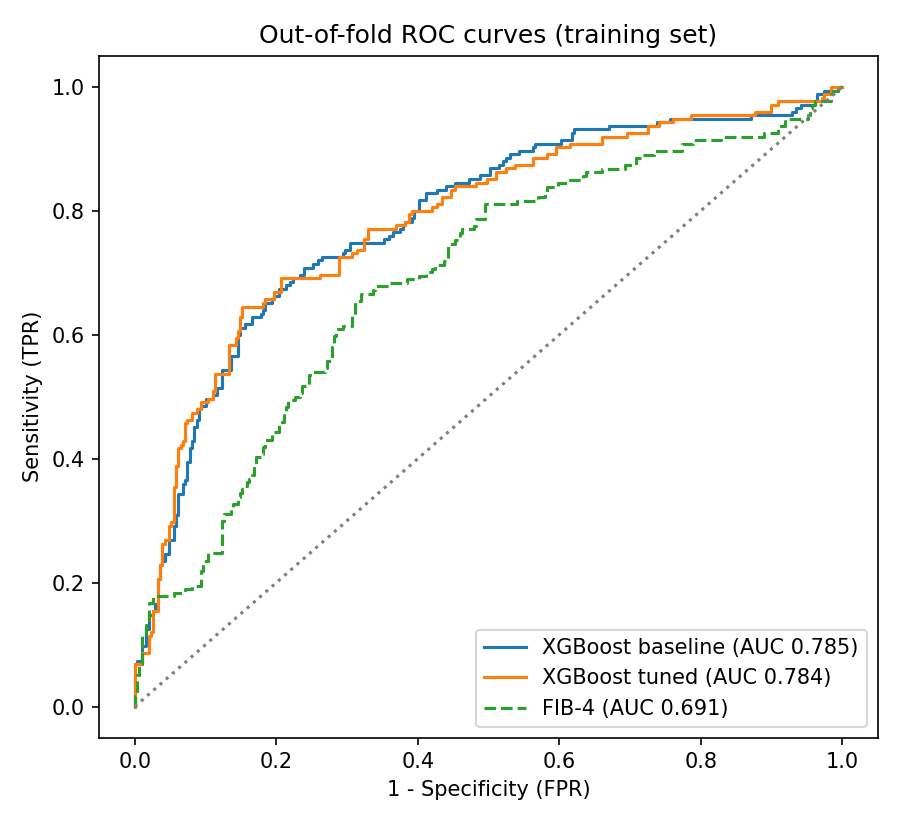

Saved → results/xgboost_roc_curve.png


In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, p in [('XGBoost baseline', oof_base), ('XGBoost tuned', oof_tuned)]:
    fpr_, tpr_, _ = roc_curve(yt, p)
    ax.plot(fpr_, tpr_, label='%s (AUC %.3f)' % (label, roc_auc_score(yt, p)))
fpr_, tpr_, _ = roc_curve(yt[ok], fib4[ok])
ax.plot(fpr_, tpr_, '--', label='FIB-4 (AUC %.3f)' % roc_auc_score(yt[ok], fib4[ok]))
ax.plot([0, 1], [0, 1], ':', color='grey')
ax.set_xlabel('1 − Specificity (FPR)')
ax.set_ylabel('Sensitivity (TPR)')
ax.set_title('Out-of-fold ROC curves (training set)')
ax.legend(loc='lower right')
plt.tight_layout()
os.makedirs('results', exist_ok=True)
plt.savefig('results/xgboost_roc_curve.png', dpi=150)
plt.show()
print('Saved → results/xgboost_roc_curve.png')

## 6c. Feature importance (tuned XGBoost)

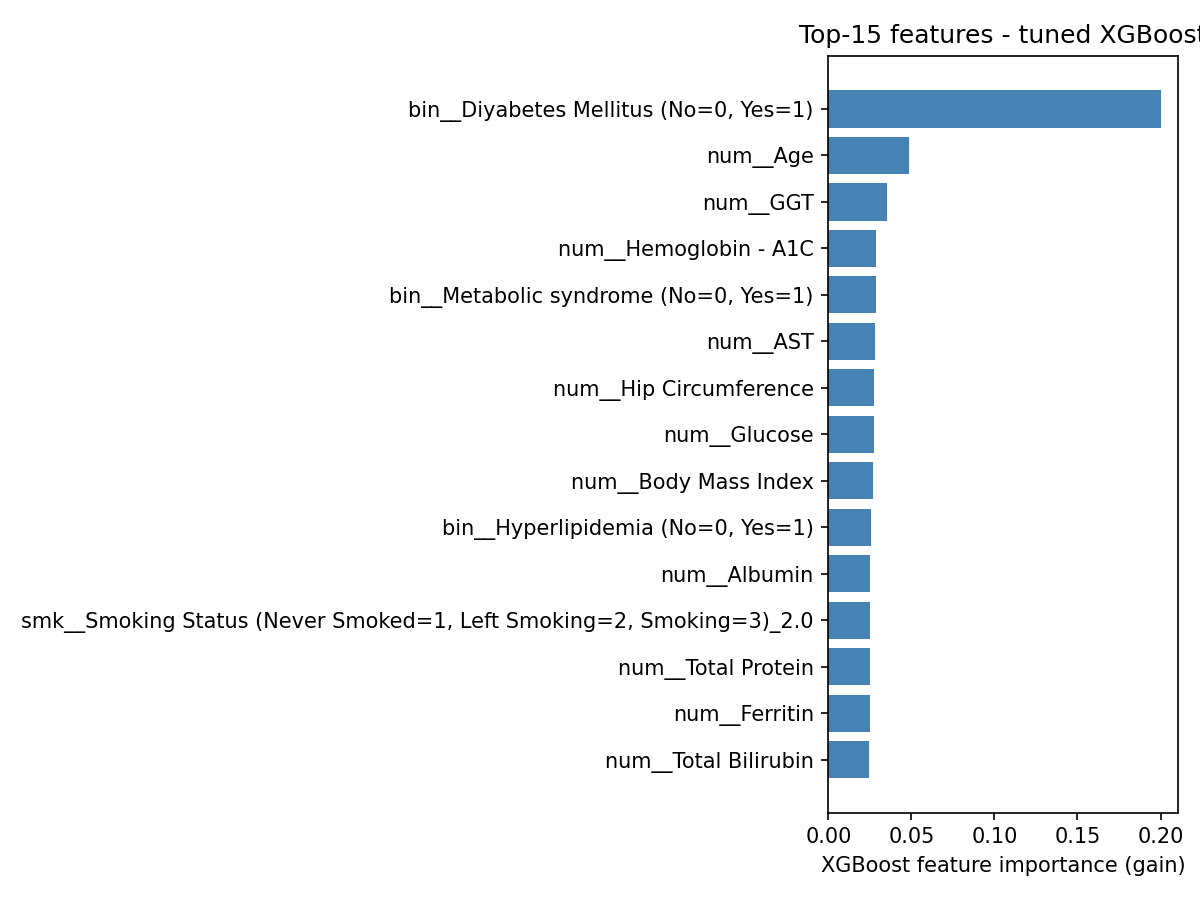

Saved → results/xgboost_feature_importance.png


In [9]:
# Fit tuned pipeline on the full training set to read importances
pipe_tuned_fit = clone(pipe_tuned).fit(X_train, y_train)
feat_names = pipe_tuned_fit.named_steps['pre'].get_feature_names_out()
importances = pipe_tuned_fit.named_steps['model'].feature_importances_

fi = (pd.DataFrame({'feature': feat_names, 'importance': importances})
        .sort_values('importance', ascending=False)
        .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(fi['feature'][:15][::-1], fi['importance'][:15][::-1])
ax.set_xlabel('XGBoost feature importance (gain)')
ax.set_title('Top-15 features — tuned XGBoost')
plt.tight_layout()
plt.savefig('results/xgboost_feature_importance.png', dpi=150)
plt.show()
print('Saved → results/xgboost_feature_importance.png')
fi.head(15)

## 7. Subgroup check: extended lab-panel group

Patients who received the extended lab panel have about twice the fibrosis rate.
A model that performs similarly in both groups is more convincing.

In [10]:
grp = data.loc[X_train.index, 'in_panel'].values
print(f"{'Group':<12} {'n':>5} {'Pos%':>6} {'XGB-tuned AUC':>14} {'FIB-4 AUC':>10}")
print('-' * 52)
for g in [0, 1]:
    m  = (grp == g)
    mk = m & ok
    xgb_auc  = roc_auc_score(yt[m],  oof_tuned[m])
    fib4_auc = roc_auc_score(yt[mk], fib4[mk])
    print(f"in_panel={g}   {m.sum():>5}  {yt[m].mean():.1%}  "
          f"       {xgb_auc:.3f}     {fib4_auc:.3f}")

Group            n   Pos%  XGB-tuned AUC  FIB-4 AUC
----------------------------------------------------
in_panel=0     246  25.2%          0.756      0.613
in_panel=1     238  47.5%          0.793      0.743


## 8. Sanity check: shuffled labels

If labels are shuffled the AUC must fall to ≈ 0.5. A clearly higher value means
something leaks into the pipeline. Also be suspicious of any real CV AUC above ≈ 0.90.

In [11]:
y_shuf = pd.Series(np.random.default_rng(SEED).permutation(yt), index=y_train.index)
rs = cross_validate(pipe_base, X_train, y_shuf, cv=cv_oof, scoring='roc_auc')
print('Shuffled-label AUC: %.3f  (should be ~0.500)' % rs['test_score'].mean())

Shuffled-label AUC: 0.551  (should be ~0.500)


## 9. Save results for merging with other models

Commit the `results/` folder. Teammates save the same kind of files for their models
(columns `p_logreg`, `p_rf`). The `patient_no` column lets all prediction files be
merged so every model is compared on exactly the same patients.

In [12]:
os.makedirs('results', exist_ok=True)

summary = {
    'baseline':    base_res,
    'tuned':       tuned_res,
    'tuned_best_params':       best_params,
    'fib4_reference_train_rows': fib4_ref,
    'setup': {
        'dataset':    CLEAN_PATH,
        'n_train':    int(len(X_train)),
        'n_test':     int(len(X_test)),
        'n_features': len(feats),
        'seed':       SEED,
    }
}
with open('results/xgboost_results.json', 'w') as f:
    json.dump(summary, f, indent=2)

pd.DataFrame({
    'patient_no':      data.loc[X_train.index, 'Patient No.'].values,
    'y':               yt,
    'fib4':            fib4,
    'in_panel':        grp,
    'p_xgb_baseline':  oof_base,
    'p_xgb_tuned':     oof_tuned,
}).to_csv('results/oof_xgboost.csv', index=False)

print('Files saved:')
print(sorted(os.listdir('results')))

Files saved:
['oof_xgboost.csv', 'xgboost_feature_importance.png', 'xgboost_results.json', 'xgboost_roc_curve.png']


## 10. Hand-over checklist

Values to give the team for the comparison table:

| Value | Where it is |
|---|---|
| CV ROC-AUC and PR-AUC (mean ± SD), recall / precision / F1 at 0.5 | Section 6 table |
| Train AUC (overfitting check) | Section 6 table |
| OOF AUC and its difference from FIB-4 with 95 % CI | Section 6 table |
| Sensitivity at specificity 0.78, specificity at sensitivity 0.80 | Section 6 table |
| Brier score (calibration) | Section 6 table |
| AUC by lab-panel group | Section 7 |
| Shuffled-label AUC (should be ≈ 0.5) | Section 8 |
| `results/xgboost_results.json` and `results/oof_xgboost.csv` | Section 9 |
| `results/xgboost_roc_curve.png` | Section 6b |
| `results/xgboost_feature_importance.png` | Section 6c |

**Do not use `X_test` yet.** The held-out test set is evaluated once, after all three
models are final and the threshold rule is agreed, with bootstrap confidence intervals
(only 121 patients, so they will be wide).